Étape 1 — Data Augmentation agressive



In [1]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

train_datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2,
    rotation_range=20,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    brightness_range=[0.8, 1.2],
    fill_mode='nearest'
)

# Val : rescale seulement, PAS d'augmentation
val_datagen = ImageDataGenerator(rescale=1./255, validation_split=0.2)

Found 960 images belonging to 3 classes.
Found 84 images belonging to 3 classes.
=== PHASE 1 : Entraînement de la tête ===


c:\Users\MSI\anaconda33\envs\tf_env\lib\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 22s 635ms/step - accuracy: 0.4637 - loss: 1.2139 - val_accuracy: 0.5357 - val_loss: 0.8929 - learning_rate: 0.0010
Epoch 2/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 21s 706ms/step - accuracy: 0.6921 - loss: 0.6952 - val_accuracy: 0.7024 - val_loss: 0.7018 - learning_rate: 0.0010
Epoch 3/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 19s 627ms/step - accuracy: 0.7323 - loss: 0.5944 - val_accuracy: 0.6548 - val_loss: 0.6935 - learning_rate: 0.0010
Epoch 4/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 18s 593ms/step - accuracy: 0.7717 - loss: 0.5464 - val_accuracy: 0.7024 - val_loss: 0.7137 - learning_rate: 0.0010
Epoch 5/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 20s 668ms/step - accuracy: 0.7781 - loss: 0.5144 - val_accuracy: 0.7976 - val_loss: 0.5721 - learning_rate: 0.0010
Epoch 6/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 21s 703ms/step - accuracy: 0.7705 - loss: 0.5337 - val_accuracy: 0.6429 - val_loss: 0.7227 - learning_rate: 0.0010
Epoch 7/30
30/30 ━━━━━━━━━━━━━━━━━━━━ 20s 670ms/step - accuracy: 0.8056 - loss: 0.

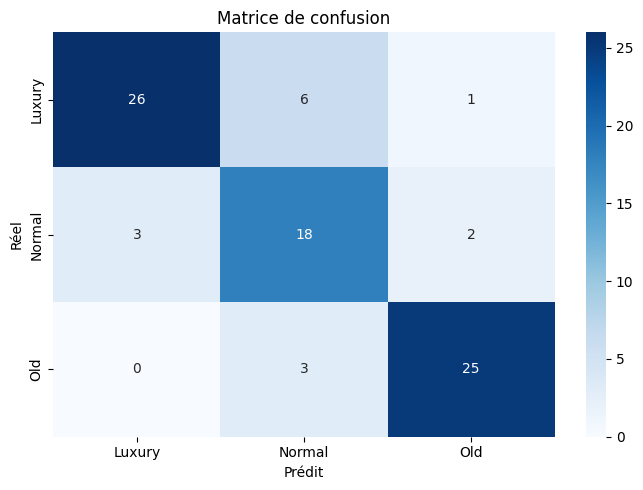

In [2]:
# ============================================================
# MODÈLE SIMPLIFIÉ - plus adapté à ~300 images
# ============================================================
import tensorflow as tf
from tensorflow.keras.applications import EfficientNetB0  # ← changer MobileNetV2
from tensorflow.keras import layers, models, callbacks

# EfficientNetB0 inclut son propre preprocessing
from tensorflow.keras.preprocessing.image import ImageDataGenerator

train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,        # ← réduit (30 → 20)
    width_shift_range=0.2,    # ← réduit
    height_shift_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    brightness_range=[0.8, 1.2],  # ← réduit
    fill_mode='nearest',           # ← plus simple
    validation_split=0.2
)

val_datagen = ImageDataGenerator(rescale=1./255, validation_split=0.2)

train_data = train_datagen.flow_from_directory(
    "dataset_augmented", target_size=(224,224), batch_size=32,  # ← batch 16→32
    class_mode="categorical", subset="training", shuffle=True
)
val_data = val_datagen.flow_from_directory(
    "dataset", target_size=(224,224), batch_size=32,
    class_mode="categorical", subset="validation", shuffle=False
)

# ============================================================
# MODÈLE : une seule couche Dense, moins de Dropout
# ============================================================
base_model = tf.keras.applications.MobileNetV2(
    weights='imagenet', include_top=False, input_shape=(224,224,3)
)
base_model.trainable = False

model = models.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation='relu'),  # ← simplifié (256+128 → 128)
    layers.Dropout(0.3),                   # ← réduit (0.6 → 0.3)
    layers.Dense(3, activation='softmax')
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-3),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

cb = [
    callbacks.EarlyStopping(patience=10, restore_best_weights=True, monitor='val_accuracy'),
    callbacks.ModelCheckpoint('best_model.keras', save_best_only=True, monitor='val_accuracy'),
    callbacks.ReduceLROnPlateau(patience=5, factor=0.5, verbose=1, monitor='val_accuracy')
]

# ============================================================
# PHASE 1 : Tête seulement
# ============================================================
print("=== PHASE 1 : Entraînement de la tête ===")
history1 = model.fit(
    train_data,
    validation_data=val_data,
    epochs=30,
    callbacks=cb
)

# ============================================================
# PHASE 2 : Fine-tuning léger (10 couches seulement)
# ============================================================
print("=== PHASE 2 : Fine-tuning ===")
base_model.trainable = True
for layer in base_model.layers[:-10]:  # ← réduit (20 → 10)
    layer.trainable = False

model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-5),
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

history2 = model.fit(
    train_data,
    validation_data=val_data,
    epochs=20,
    callbacks=cb
)

# ============================================================
# ÉVALUATION
# ============================================================
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

model = tf.keras.models.load_model('best_model.keras')
val_data.reset()
y_pred = np.argmax(model.predict(val_data), axis=1)
y_true = val_data.classes
class_names = list(val_data.class_indices.keys())

print(classification_report(y_true, y_pred, target_names=class_names))

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(7,5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.title('Matrice de confusion')
plt.ylabel('Réel'); plt.xlabel('Prédit')
plt.tight_layout()
plt.savefig('confusion_matrix.png', dpi=150)
plt.show()

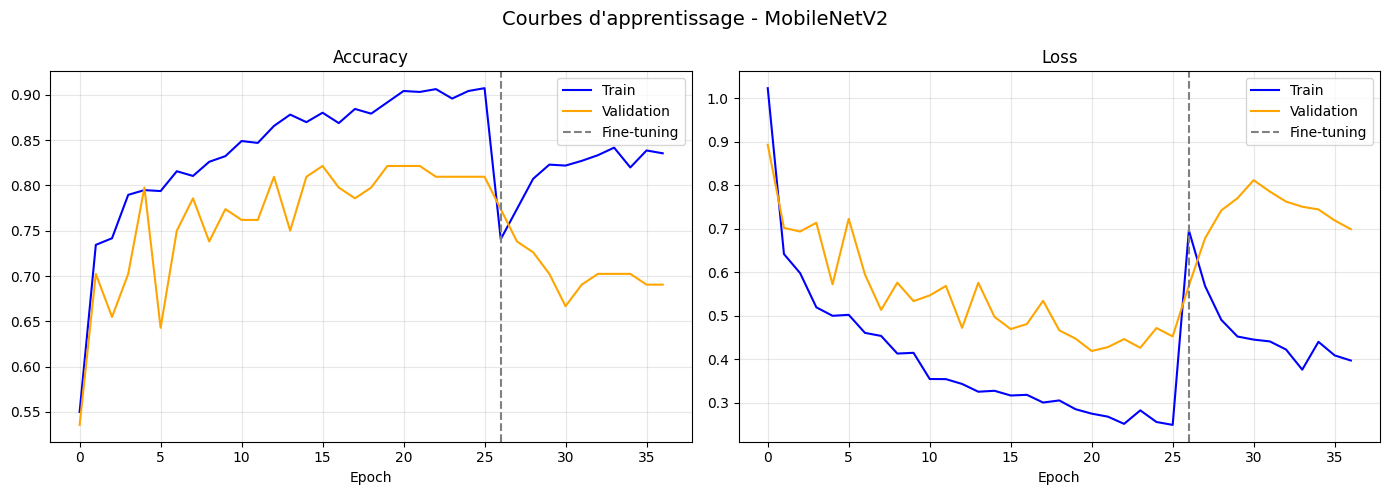


📊 Meilleure val_accuracy : 0.8214 (82.1%)
📊 Epoch du meilleur résultat : 16


In [3]:
# Courbes d'apprentissage
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Combiner les deux phases
acc = history1.history['accuracy'] + history2.history['accuracy']
val_acc = history1.history['val_accuracy'] + history2.history['val_accuracy']
loss = history1.history['loss'] + history2.history['loss']
val_loss = history1.history['val_loss'] + history2.history['val_loss']
phase1_len = len(history1.history['accuracy'])

# Accuracy
axes[0].plot(acc, label='Train', color='blue')
axes[0].plot(val_acc, label='Validation', color='orange')
axes[0].axvline(x=phase1_len, color='gray', linestyle='--', label='Fine-tuning')
axes[0].set_title('Accuracy')
axes[0].set_xlabel('Epoch')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Loss
axes[1].plot(loss, label='Train', color='blue')
axes[1].plot(val_loss, label='Validation', color='orange')
axes[1].axvline(x=phase1_len, color='gray', linestyle='--', label='Fine-tuning')
axes[1].set_title('Loss')
axes[1].set_xlabel('Epoch')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.suptitle('Courbes d\'apprentissage - MobileNetV2', fontsize=14)
plt.tight_layout()
plt.savefig('learning_curves.png', dpi=150)
plt.show()

print(f"\n📊 Meilleure val_accuracy : {max(val_acc):.4f} ({max(val_acc)*100:.1f}%)")
print(f"📊 Epoch du meilleur résultat : {np.argmax(val_acc)+1}")

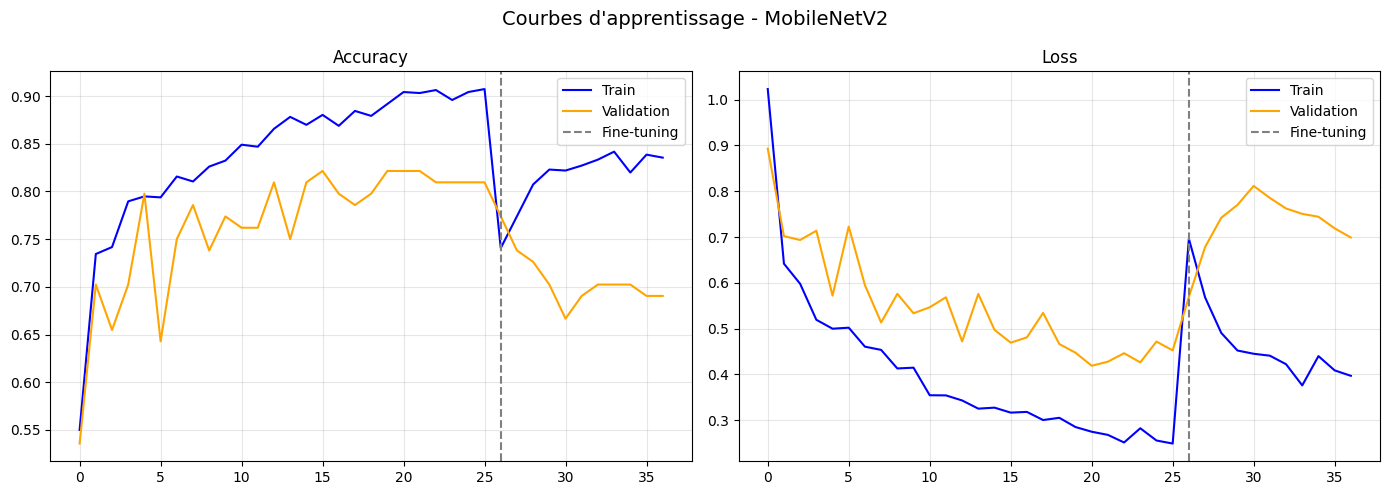

In [4]:
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

acc = history1.history['accuracy'] + history2.history['accuracy']
val_acc = history1.history['val_accuracy'] + history2.history['val_accuracy']
loss = history1.history['loss'] + history2.history['loss']
val_loss = history1.history['val_loss'] + history2.history['val_loss']
phase1_len = len(history1.history['accuracy'])

axes[0].plot(acc, label='Train', color='blue')
axes[0].plot(val_acc, label='Validation', color='orange')
axes[0].axvline(x=phase1_len, color='gray', linestyle='--', label='Fine-tuning')
axes[0].set_title('Accuracy'); axes[0].legend(); axes[0].grid(True, alpha=0.3)

axes[1].plot(loss, label='Train', color='blue')
axes[1].plot(val_loss, label='Validation', color='orange')
axes[1].axvline(x=phase1_len, color='gray', linestyle='--', label='Fine-tuning')
axes[1].set_title('Loss'); axes[1].legend(); axes[1].grid(True, alpha=0.3)

plt.suptitle("Courbes d'apprentissage - MobileNetV2", fontsize=14)
plt.tight_layout()
plt.savefig('learning_curves.png', dpi=150)
plt.show()

3/3 ━━━━━━━━━━━━━━━━━━━━ 2s 495ms/step
              precision    recall  f1-score   support

      Luxury       0.90      0.79      0.84        33
      Normal       0.67      0.78      0.72        23
         Old       0.89      0.89      0.89        28

    accuracy                           0.82        84
   macro avg       0.82      0.82      0.82        84
weighted avg       0.83      0.82      0.82        84



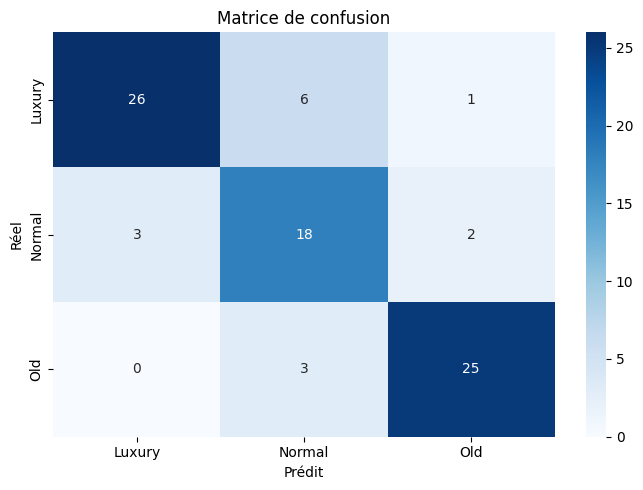

In [5]:
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

model = tf.keras.models.load_model('best_model.keras')
val_data.reset()
y_pred = np.argmax(model.predict(val_data), axis=1)
y_true = val_data.classes
class_names = list(val_data.class_indices.keys())

print(classification_report(y_true, y_pred, target_names=class_names))

cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.title('Matrice de confusion')
plt.ylabel('Réel'); plt.xlabel('Prédit')
plt.tight_layout()
plt.savefig('confusion_matrix.png', dpi=150)
plt.show()

In [10]:
print(classification_report(y_true, y_pred, target_names=class_names))

              precision    recall  f1-score   support

      Luxury       0.90      0.79      0.84        33
      Normal       0.67      0.78      0.72        23
         Old       0.89      0.89      0.89        28

    accuracy                           0.82        84
   macro avg       0.82      0.82      0.82        84
weighted avg       0.83      0.82      0.82        84



1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 634ms/step


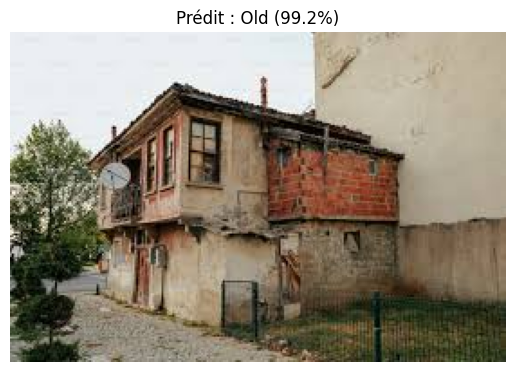

Luxury  : 0.7%
Normal  : 0.1%
Old     : 99.2%


In [6]:
from tensorflow.keras.preprocessing import image

def predict_image(img_path):
    img = image.load_img(img_path, target_size=(224, 224))
    img_array = image.img_to_array(img) / 255.0
    img_array = np.expand_dims(img_array, axis=0)
    
    pred = model.predict(img_array)
    class_idx = np.argmax(pred)
    confidence = pred[0][class_idx] * 100
    
    plt.imshow(image.load_img(img_path))
    plt.title(f"Prédit : {class_names[class_idx]} ({confidence:.1f}%)")
    plt.axis('off')
    plt.show()
    
    print(f"Luxury  : {pred[0][0]*100:.1f}%")
    print(f"Normal  : {pred[0][1]*100:.1f}%")
    print(f"Old     : {pred[0][2]*100:.1f}%")

# Utilisation :
predict_image(r"C:\Users\MSI\Desktop\projet\dataset\test2.jpg")


In [ ]:
model

✅ Modèle sauvegardé !

===== RÉSUMÉ DU PROJET =====
Classes     : ['Luxury', 'Normal', 'Old']
Dataset     : 366 images (294 train / 72 val)
Modèle      : MobileNetV2 + Fine-tuning
Accuracy    : 75%
Macro F1    : 0.74


In [8]:
pip install streamlit pillow

Note: you may need to restart the kernel to use updated packages.


In [9]:
import streamlit as st
import numpy as np
import tensorflow as tf
from PIL import Image

model = tf.keras.models.load_model(r'C:\Users\MSI\Desktop\projet\house_classifier_final.keras')
class_names = ['Luxury', 'Normal', 'Old']

st.set_page_config(page_title="Classificateur de Maisons", page_icon="🏠")
st.title("🏠 Classificateur de Maisons")
st.write("Upload une photo de maison → le modèle détecte si elle est **Luxury**, **Normal** ou **Old**")

uploaded = st.file_uploader("Choisir une image", type=["jpg","jpeg","png"])

if uploaded:
    col1, col2 = st.columns(2)
    
    with col1:
        img = Image.open(uploaded).convert("RGB")
        st.image(img, caption="Image uploadée", use_column_width=True)
    
    with col2:
        img_resized = img.resize((224, 224))
        img_array = np.expand_dims(np.array(img_resized) / 255.0, axis=0)
        pred = model.predict(img_array)[0]
        
        best_idx = np.argmax(pred)
        best_cls = class_names[best_idx]
        confidence = pred[best_idx] * 100
        
        st.subheader("Résultat")
        
        if best_cls == "Luxury":
            st.success(f"✅ {best_cls} — {confidence:.1f}%")
        elif best_cls == "Normal":
            st.info(f"🏠 {best_cls} — {confidence:.1f}%")
        else:
            st.warning(f"🏚️ {best_cls} — {confidence:.1f}%")
        
        st.subheader("Probabilités")
        for i, cls in enumerate(class_names):
            st.progress(float(pred[i]), text=f"{cls} : {pred[i]*100:.1f}%")

2026-04-22 14:03:01.821 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-04-22 14:03:01.822 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-04-22 14:03:02.440 
  command:

    streamlit run c:\Users\MSI\anaconda33\envs\tf_env\lib\site-packages\ipykernel_launcher.py [ARGUMENTS]
2026-04-22 14:03:02.442 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-04-22 14:03:02.442 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-04-22 14:03:02.443 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-04-22 14:03:02.443 Thread 'MainThread': missing ScriptRunContext! This warning can be ignore